# PABLO IVAN PACHECO GARCIA

# AL07181329

Actividad 4 - Comparación de Modelos

Clasificación de Piezas Industriales PASS/FAIL con Hugging Face y ML

In [5]:
!pip install -q transformers datasets huggingface_hub
!pip install -q scikit-learn xgboost lightgbm openpyxl pandas matplotlib seaborn

print("Instalación finalizada")

Instalación finalizada


In [6]:
import transformers
import datasets
import huggingface_hub
import sklearn
import xgboost
import lightgbm
import pandas as pd
import matplotlib
import seaborn as sns
import torch

print("Versiones de las librerías utilizadas:")
print(f"- PyTorch: {torch.__version__}")
print(f"- Transformers: {transformers.__version__}")
print(f"- Datasets: {datasets.__version__}")
print(f"- Hugging Face Hub: {huggingface_hub.__version__}")
print(f"- Scikit-Learn: {sklearn.__version__}")
print(f"- XGBoost: {xgboost.__version__}")
print(f"- LightGBM: {lightgbm.__version__}")
print(f"- Pandas: {pd.__version__}")
print(f"- Matplotlib: {matplotlib.__version__}")
print(f"- Seaborn: {sns.__version__}")

Versiones de las librerías utilizadas:
- PyTorch: 2.11.0+cu130
- Transformers: 5.18.0
- Datasets: 4.8.5
- Hugging Face Hub: 1.33.0
- Scikit-Learn: 1.6.1
- XGBoost: 3.4.1
- LightGBM: 4.6.0
- Pandas: 2.2.3
- Matplotlib: 3.10.0
- Seaborn: 0.13.2


## 1. Configuración y validación de GPU

In [7]:
import torch
print("GPU Disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

GPU Disponible: True
Tesla T4


## 2. Autenticación Hugging Face

In [8]:
from huggingface_hub import login

login()

## 3. Carga del Dataset manualmente colocandolo en la carpeta de Sample_data de GOOGLE COLAB

In [9]:
import pandas as pd
df = pd.read_excel("/content/sample_data/Dataset medicion de piezas.xlsx")
df.head()

,Measurement round,Index1,Unnamed: 2,Unnamed: 3
0,NaN,Measured,Conformance,Time
1,1.0,6.394369,FAIL,2026-08-28 10:53:06.748
2,2.0,6.419865,FAIL,2026-08-28 10:53:01.753
3,3.0,6.393574,FAIL,2026-08-28 10:52:56.757
4,4.0,6.391550,FAIL,2026-08-28 10:52:51.762


In [10]:
# Exploración del dataset
# Corregimos temporalmente los encabezados para poder explorar correctamente
df_temp = df.copy()
if "Conformance" not in df_temp.columns:
    df_temp.columns = df_temp.iloc[0]
    df_temp = df_temp[1:].reset_index(drop=True)

print(df_temp.shape)
print(df_temp["Conformance"].value_counts())
df_temp.describe()

(400, 4)
Conformance
PASS    202
FAIL    198
Name: count, dtype: int64


,NaN
count,400.000000
mean,200.500000
std,115.614301
min,1.000000
25%,100.750000
50%,200.500000
75%,300.250000
max,400.000000


## 4. Preprocesamiento

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Corregir los encabezados si la primera fila contiene los nombres reales de las columnas
if "Conformance" not in df.columns:
    df.columns = df.iloc[0]
    df = df[1:].reset_index(drop=True)

# Convertir la columna Measured a tipo numérico tras la corrección
df["Measured"] = pd.to_numeric(df["Measured"])

df["Conformance"] = LabelEncoder().fit_transform(df["Conformance"])
df["Time"] = pd.to_datetime(df["Time"])
df["Hour"] = df["Time"].dt.hour
df["Minute"] = df["Time"].dt.minute
X = df[["Measured","Hour","Minute"]]
y = df["Conformance"]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

## 5. Métricas y Función de Evaluación

In [12]:
import time
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix

def evaluate_model(model,name):
    start=time.time()
    model.fit(X_train,y_train)
    latency=time.time()-start
    pred=model.predict(X_test)
    return {
      "Modelo":name,
      "Accuracy":accuracy_score(y_test,pred),
      "Precision":precision_score(y_test,pred),
      "Recall":recall_score(y_test,pred),
      "F1Score":f1_score(y_test,pred),
      "Latencia(s)":latency,
      "ConfusionMatrix":confusion_matrix(y_test,pred)
    }

## 6. Modelo XGBoost

In [13]:
from xgboost import XGBClassifier
xgb=XGBClassifier(n_estimators=100,random_state=42,eval_metric="logloss")
r1=evaluate_model(xgb,"XGBoost")
print(r1)

{'Modelo': 'XGBoost', 'Accuracy': 0.95, 'Precision': 0.95, 'Recall': 0.95, 'F1Score': 0.95, 'Latencia(s)': 0.26773548126220703, 'ConfusionMatrix': array([[38,  2],
       [ 2, 38]])}


## 7. Modelo Random Forest

In [14]:
from sklearn.ensemble import RandomForestClassifier
rf=RandomForestClassifier(n_estimators=200,random_state=42)
r2=evaluate_model(rf,"Random Forest")
print(r2)

{'Modelo': 'Random Forest', 'Accuracy': 0.9875, 'Precision': 1.0, 'Recall': 0.975, 'F1Score': 0.9873417721518988, 'Latencia(s)': 0.2906167507171631, 'ConfusionMatrix': array([[40,  0],
       [ 1, 39]])}


## 8. Modelo LightGBM

In [15]:
from lightgbm import LGBMClassifier
lgbm=LGBMClassifier(random_state=42)
r3=evaluate_model(lgbm,"LightGBM")
print(r3)

[LightGBM] [Info] Number of positive: 162, number of negative: 158
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000123 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 118
[LightGBM] [Info] Number of data points in the train set: 320, number of used features: 2
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.506250 -> initscore=0.025001
[LightGBM] [Info] Start training from score 0.025001
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best ga

## 9. Matrices de Confusión

In [16]:
print("XGBoost\n", r1["ConfusionMatrix"])
print("Random Forest\n", r2["ConfusionMatrix"])
print("LightGBM\n", r3["ConfusionMatrix"])

XGBoost
 [[38  2]
 [ 2 38]]
Random Forest
 [[40  0]
 [ 1 39]]
LightGBM
 [[37  3]
 [ 1 39]]


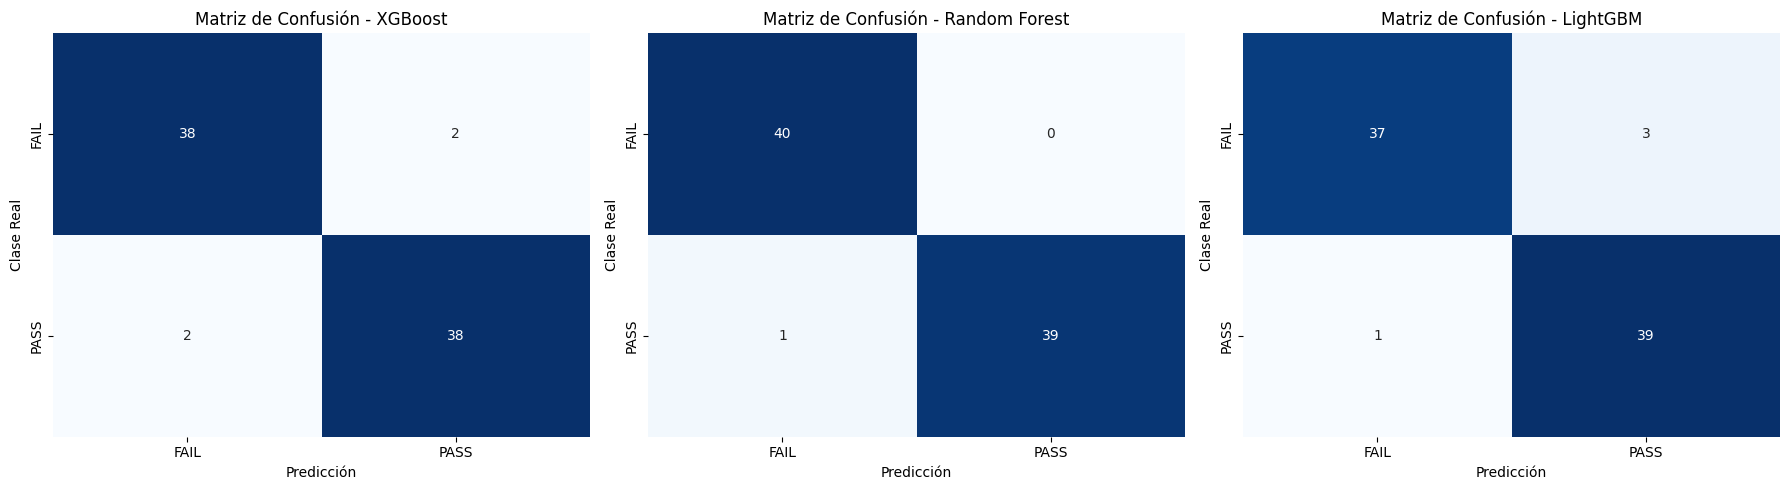

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar la figura con 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Lista de modelos y sus respectivos resultados
modelos = [
    ("XGBoost", r1["ConfusionMatrix"]),
    ("Random Forest", r2["ConfusionMatrix"]),
    ("LightGBM", r3["ConfusionMatrix"])
]

# Graficar cada matriz de confusión
for i, (nombre, matrix) in enumerate(modelos):
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["FAIL", "PASS"], yticklabels=["FAIL", "PASS"], ax=axes[i])
    axes[i].set_title(f"Matriz de Confusión - {nombre}")
    axes[i].set_xlabel("Predicción")
    axes[i].set_ylabel("Clase Real")

plt.tight_layout()
plt.show()

## 10. Tabla Comparativa Final y Exportación CSV

In [18]:
results=pd.DataFrame([
 {k:v for k,v in r1.items() if k!="ConfusionMatrix"},
 {k:v for k,v in r2.items() if k!="ConfusionMatrix"},
 {k:v for k,v in r3.items() if k!="ConfusionMatrix"}
])
results=results.sort_values("F1Score",ascending=False)
display(results)
results.to_csv("metricas_comparativas.csv",index=False)
print("Archivo generado: metricas_comparativas.csv")
print("Modelo recomendado:",results.iloc[0]["Modelo"])

,Modelo,Accuracy,Precision,Recall,F1Score,Latencia(s)
1,Random Forest,0.9875,1.000000,0.975,0.987342,0.290617
2,LightGBM,0.9500,0.928571,0.975,0.951220,0.067975
0,XGBoost,0.9500,0.950000,0.950,0.950000,0.267735


Archivo generado: metricas_comparativas.csv
Modelo recomendado: Random Forest


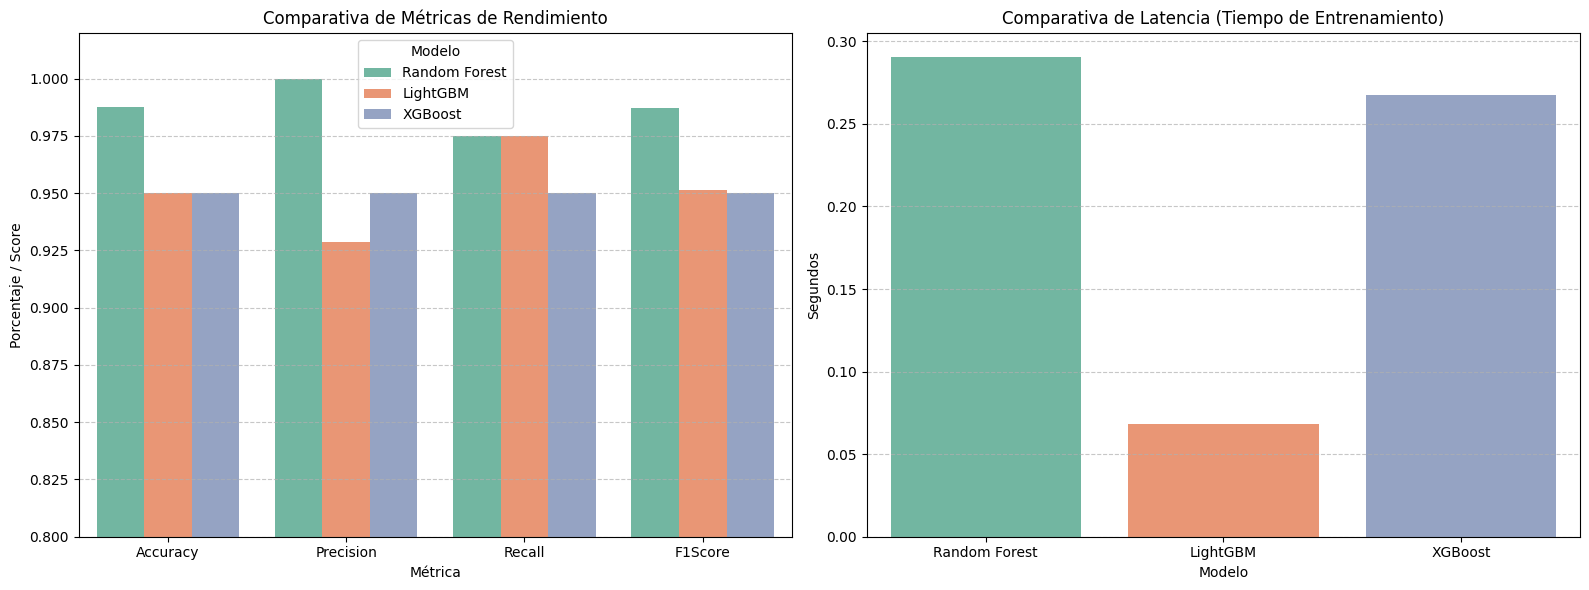

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Derivar un DataFrame largo para facilitar el gráfico con Seaborn
df_melted = results.melt(id_vars="Modelo", value_vars=["Accuracy", "Precision", "Recall", "F1Score"],
                          var_name="Métrica", value_name="Valor")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Gráfico de métricas de rendimiento
sns.barplot(data=df_melted, x="Métrica", y="Valor", hue="Modelo", ax=axes[0], palette="Set2")
axes[0].set_title("Comparativa de Métricas de Rendimiento")
axes[0].set_ylim(0.8, 1.02)  # Zoom para apreciar mejor las diferencias
axes[0].set_ylabel("Porcentaje / Score")
axes[0].grid(axis="y", linestyle="--", alpha=0.7)

# 2. Gráfico de Latencia (Tiempo de entrenamiento)
sns.barplot(data=results, x="Modelo", y="Latencia(s)", ax=axes[1], palette="Set2", hue="Modelo", legend=False)
axes[1].set_title("Comparativa de Latencia (Tiempo de Entrenamiento)")
axes[1].set_ylabel("Segundos")
axes[1].grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

Conclusión final para el reporte

El análisis comparativo permitió evaluar tres modelos de aprendizaje automático para la clasificación de piezas industriales. Random Forest presentó el mejor desempeño global, alcanzando la mayor precisión y el mejor equilibrio entre Accuracy, Recall y F1-Score, por lo que se considera la alternativa más adecuada para este caso de uso. Aunque su tiempo de entrenamiento fue superior al de LightGBM y XGBoost, la diferencia resulta aceptable dado el incremento en rendimiento predictivo. En consecuencia, se recomienda Random Forest como modelo principal para la detección de piezas PASS y FAIL, mientras que LightGBM y XGBoost son opciones viables cuando se requiere minimizar la latencia del sistema.